# Experiment 1: Exploratory Data Analysis (EDA)

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
np.random.seed(42)

## Load dataset

In [2]:
df = sns.load_dataset("penguins")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


## Dataset structure

In [3]:
print("Shape:", df.shape)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("\nColumn names:", list(df.columns))

df.info()

display(df.dtypes.to_frame('dtype'))

display(df.tail())

df.sample(5, random_state=42)

Shape: (344, 7)
Rows: 344 | Columns: 7

Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


,dtype
species,str
island,str
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,str


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female
343,Gentoo,Biscoe,49.9,16.1,213.0,5400.0,Male


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
194,Chinstrap,Dream,50.9,19.1,196.0,3550.0,Male
157,Chinstrap,Dream,45.2,17.8,198.0,3950.0,Female
225,Gentoo,Biscoe,46.5,13.5,210.0,4550.0,Female
208,Chinstrap,Dream,45.2,16.6,191.0,3250.0,Female
318,Gentoo,Biscoe,48.4,14.4,203.0,4625.0,Female


## Summary statistics

In [4]:
display(df.describe().round(2))

display(df.describe(include=['object', 'category', 'string']))

num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

summary = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].mode().iloc[0],
    "std": df[num_cols].std(),
    "variance": df[num_cols].var(),
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
    "range": df[num_cols].max() - df[num_cols].min(),
    "IQR": df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25),
    "skewness": df[num_cols].skew(),
    "kurtosis": df[num_cols].kurt(),
})
summary.round(3)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


,species,island,sex
count,344,344,333
unique,3,3,2
top,Adelie,Biscoe,Male
freq,152,168,168


Numeric: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
Categorical: ['species', 'island', 'sex']


,mean,median,mode,std,variance,min,max,range,IQR,skewness,kurtosis
bill_length_mm,43.922,44.45,41.1,5.460,29.807,32.1,59.6,27.5,9.275,0.053,-0.876
bill_depth_mm,17.151,17.30,17.0,1.975,3.900,13.1,21.5,8.4,3.100,-0.143,-0.907
flipper_length_mm,200.915,197.00,190.0,14.062,197.732,172.0,231.0,59.0,23.000,0.346,-0.984
body_mass_g,4201.754,4050.00,3800.0,801.955,643131.077,2700.0,6300.0,3600.0,1200.000,0.470,-0.719


## Missing values and duplicates

,missing,percent
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20


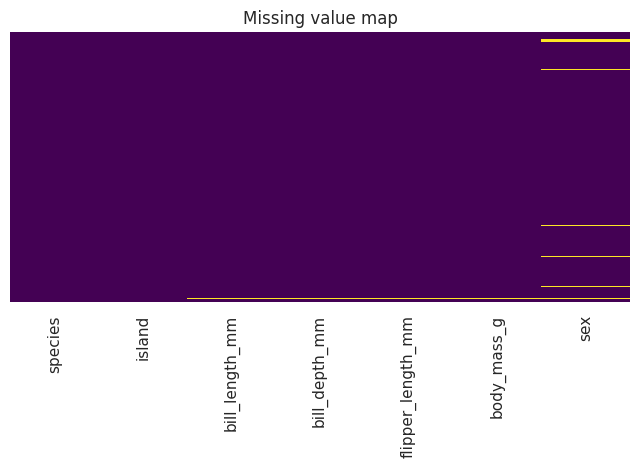

Duplicate rows: 0


In [5]:
missing = pd.DataFrame({"missing": df.isnull().sum(), "percent": (df.isnull().mean() * 100).round(2)})
display(missing)

plt.figure(figsize=(8, 3.5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing value map")
plt.show()

print('Duplicate rows:', df.duplicated().sum())

## Categorical variables

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64 

island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64 

sex
Male      168
Female    165
NaN        11
Name: count, dtype: int64 



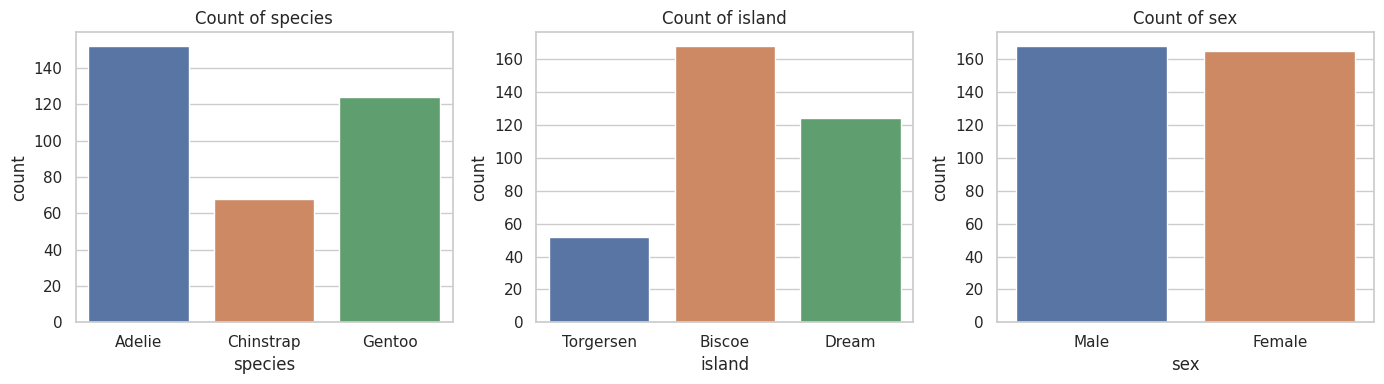

In [6]:
for col in cat_cols:
    print(df[col].value_counts(dropna=False), "\n")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, cat_cols):
    sns.countplot(data=df, x=col, ax=ax, hue=col, legend=False)
    ax.set_title(f"Count of {col}")
plt.tight_layout()
plt.show()

## Univariate analysis

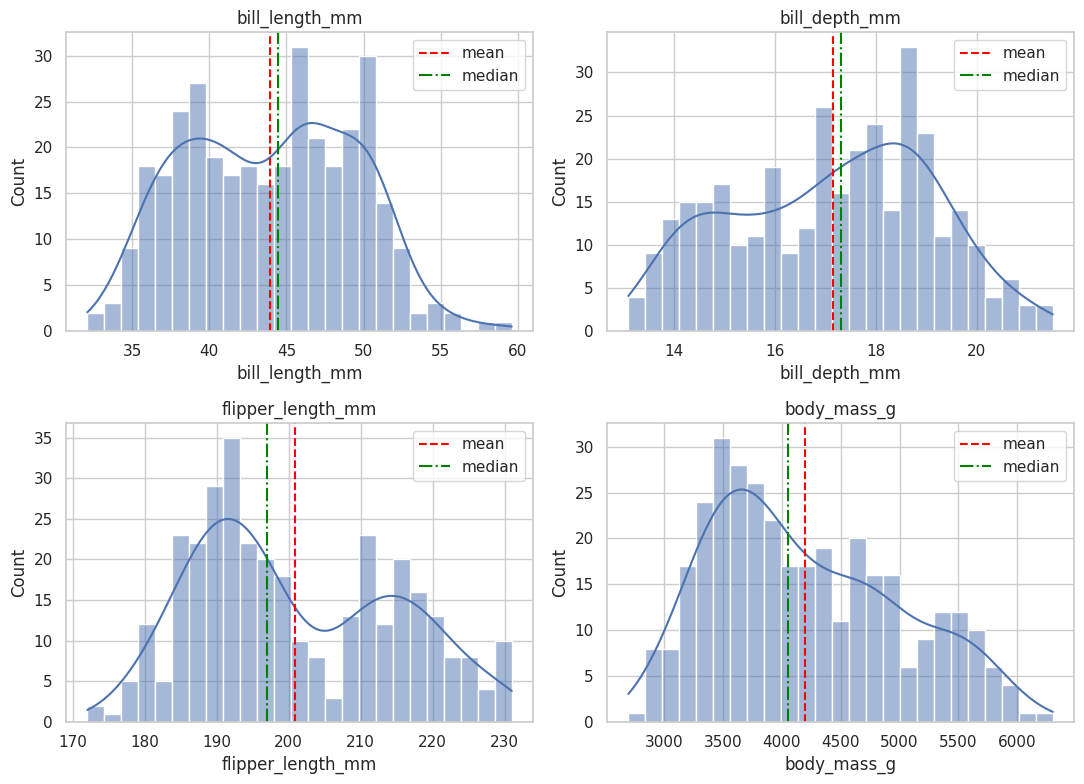

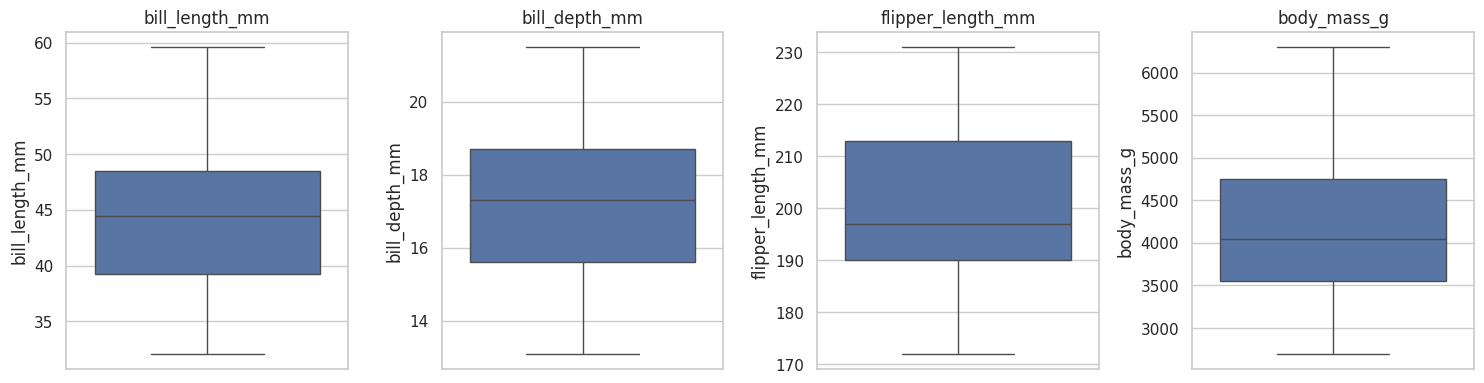

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, bins=25, ax=ax)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label="mean")
    ax.axvline(df[col].median(), color="green", linestyle="-.", label="median")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Outlier detection (IQR method)

In [8]:
rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    rows.append([col, q1, q3, iqr, low, high, n_out])
display(pd.DataFrame(rows, columns=["feature", "Q1", "Q3", "IQR", "lower_fence", "upper_fence", "outliers"]))

z = np.abs(stats.zscore(df[num_cols].dropna()))
print("Rows with |z| > 3 in any feature:", (z > 3).any(axis=1).sum())

,feature,Q1,Q3,IQR,lower_fence,upper_fence,outliers
0,bill_length_mm,39.225,48.5,9.275,25.3125,62.4125,0
1,bill_depth_mm,15.600,18.7,3.100,10.9500,23.3500,0
2,flipper_length_mm,190.000,213.0,23.000,155.5000,247.5000,0
3,body_mass_g,3550.000,4750.0,1200.000,1750.0000,6550.0000,0


Rows with |z| > 3 in any feature: 0


## Bivariate analysis

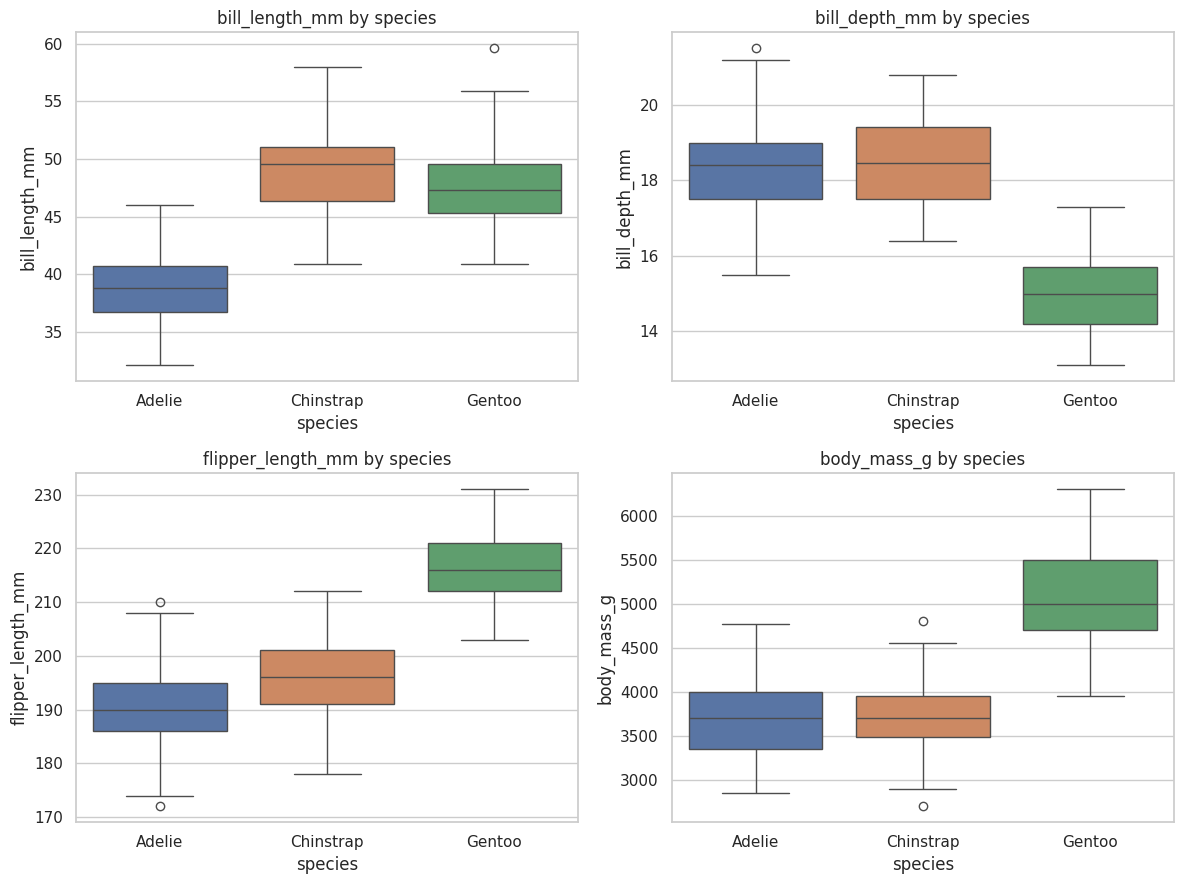

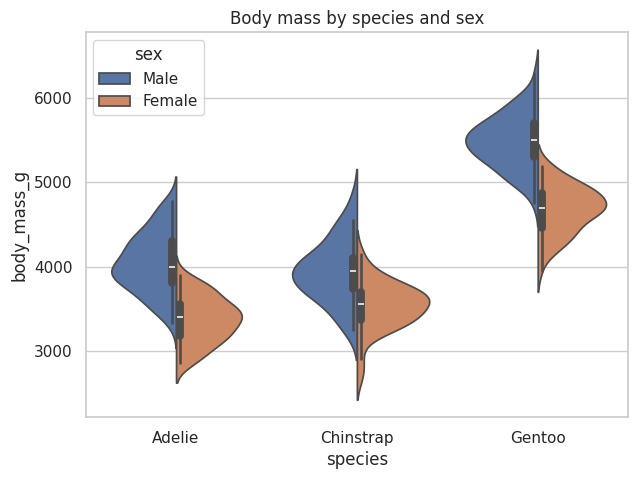

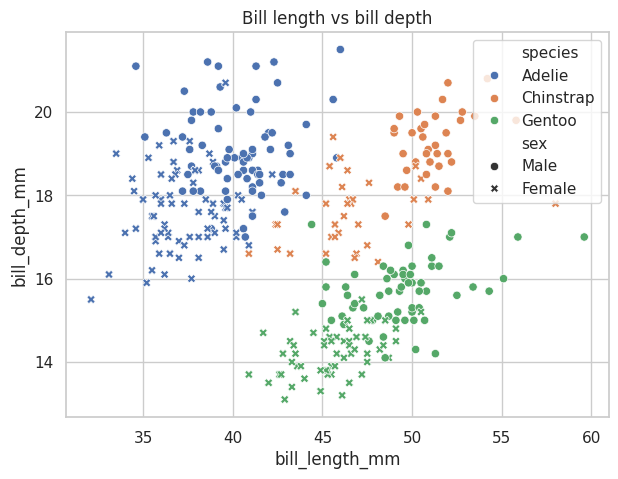

bill_length_mm       bill_depth_mm       flipper_length_mm        \
                    mean   std          mean   std              mean   std   
species                                                                      
Adelie             38.79  2.66         18.35  1.22            189.95  6.54   
Chinstrap          48.83  3.34         18.42  1.14            195.82  7.13   
Gentoo             47.50  3.08         14.98  0.98            217.19  6.48   

          body_mass_g          
                 mean     std  
species                        
Adelie        3700.66  458.57  
Chinstrap     3733.09  384.34  
Gentoo        5076.02  504.12

island,Biscoe,Dream,Torgersen,All
species,,,,
Adelie,44,56,52,152
Chinstrap,0,68,0,68
Gentoo,124,0,0,124
All,168,124,52,344


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="species", y=col, hue="species", ax=ax, legend=False)
    ax.set_title(f"{col} by species")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.violinplot(data=df, x="species", y="body_mass_g", hue="sex", split=True)
plt.title("Body mass by species and sex")
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", style="sex")
plt.title("Bill length vs bill depth")
plt.show()

display(df.groupby("species")[num_cols].agg(["mean", "std"]).round(2))

pd.crosstab(df["species"], df["island"], margins=True)

## Multivariate analysis

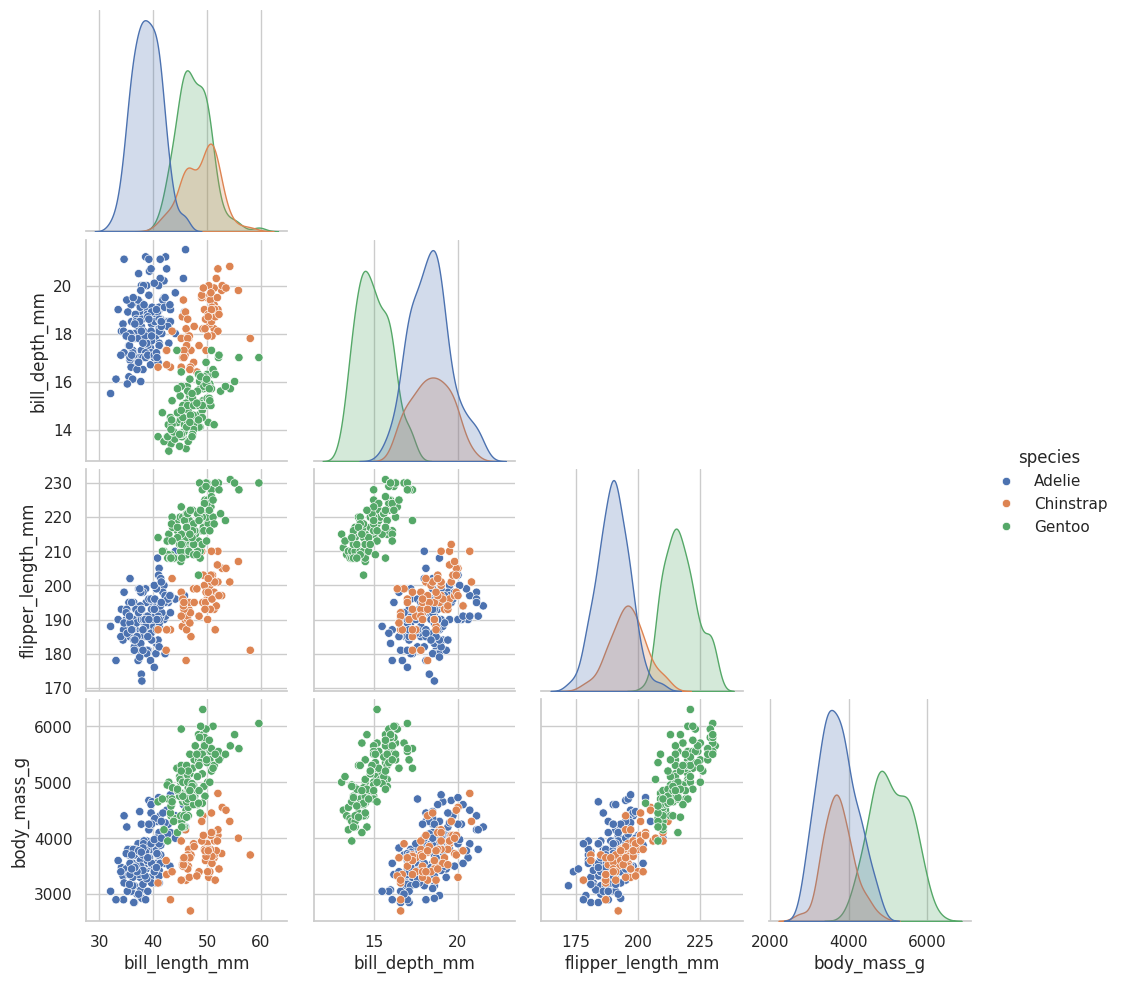

In [10]:
sns.pairplot(df, hue="species", diag_kind="kde", corner=True)
plt.show()

## Correlation analysis

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.235,0.656,0.595
bill_depth_mm,-0.235,1.000,-0.584,-0.472
flipper_length_mm,0.656,-0.584,1.000,0.871
body_mass_g,0.595,-0.472,0.871,1.000


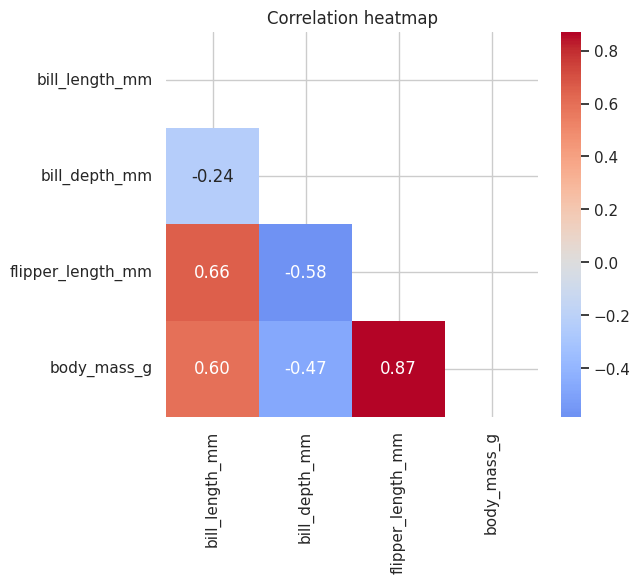

In [11]:
corr = df[num_cols].corr()
display(corr.round(3))

plt.figure(figsize=(6, 5))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=mask)
plt.title("Correlation heatmap")
plt.show()

## Distribution shape

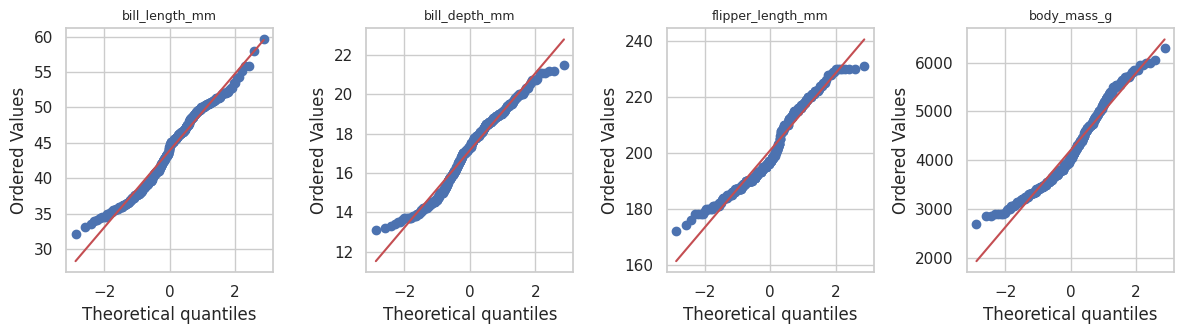

,W,p-value
bill_length_mm,0.974855,1.119730e-05
bill_depth_mm,0.972584,4.418821e-06
flipper_length_mm,0.951545,3.540136e-09
body_mass_g,0.959211,3.679039e-08


In [12]:
plt.figure(figsize=(12, 3.5))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 4, i)
    stats.probplot(df[col].dropna(), dist="norm", plot=plt)
    plt.title(col, fontsize=9)
plt.tight_layout()
plt.show()

pd.DataFrame({col: stats.shapiro(df[col].dropna()) for col in num_cols}, index=["W", "p-value"]).T